In [6]:
using Pkg
Pkg.activate("/Users/alia/Desktop/envs/ants")
using Plots
using DifferentialEquations
using LaTeXStrings
using NLsolve
using IntervalArithmetic, IntervalArithmetic.Symbols, IntervalRootFinding
using LinearAlgebra
using Plots.PlotMeasures

xgfs_normal12 = [(235, 172, 35), (184, 0, 88), (0, 140, 249), (0, 110, 0), (0, 187, 173), (209, 99, 230), (178, 69, 2), (255, 146, 135), (89, 84, 214), (0, 198, 248), (135, 133, 0), (0, 167, 108), (189, 189, 189)]
pal = [RGB(r/255, g/255, b/255) for (r,g,b) in xgfs_normal12]
#pal = palette

  Activating project at `~/Desktop/envs/ants`


In [55]:
function normal(x)
    b = size(x)[1]
    return b*(x .+ 1) / (sum(x)+b)
end

function model_7d_avg!(dx,x,p,t)
    (alphaC,alphaB,alphaT,beta,omegaC,omegaB,k,
    n,u,aC,aB,aT,aBC,aTC,bC,aCB,aTB,bB,aCT,aBT,bT,tau,gamma,b0C,b0B,b0T)=p
    S,C,B,T,xC,xB,xT = x
    H = 1 - S - B - C - T
    xCn,xBn,xTn = normal([xC,xB,xT])
    dx[1] = (-(alphaC*xCn+alphaB*xBn+alphaT*xTn)*S) + gamma*H
    dx[2] = alphaC*xCn*S - omegaC*C/(1+ (C/k)^n)
    dx[3] = alphaB*xBn*S - omegaB*B/(1+ (C/k)^n)
    dx[4] = alphaT*xTn*S - beta*T
    dx[5] = 1/tau*(-xC + tanh(u*(aC*xC + aBC*xB + aTC*xT + bC*C) + b0C))
    dx[6] = 1/tau*(-xB + tanh(u*(aB*xB + aCB*xC + aTB*xT + bB*C) + b0B))
    dx[7] = 1/tau*(-xT + tanh(u*(aT*xT + aCT*xC + aBT*xB + bT*C) + b0T))
    return nothing
end

function model_4d!(dx,x,p,t)
    (alphaC,alphaB,alphaT,beta,omegaC,omegaB,k,n,gamma)=p
    S,C,B,T = x
    H = 1 - S - B - C - T
    dx[1] = (-(alphaC+alphaB+alphaT)*S) + gamma*H
    dx[2] = alphaC*S - omegaC*C/(1+ (C/k)^n)
    dx[3] = alphaB*S - omegaB*B/(1+ (C/k)^n)
    dx[4] = alphaT*S - beta*T
    return nothing
end

function model_4d_in_out!(dx,x,p,t)
    (alphaC,alphaB,alphaT,beta,omegaC,omegaB,k,n,gamma)=p
    S,C,B,T = x
    H = 1 - S - B - C - T
    dx[1] = (-(alphaC+alphaB+alphaT)*S) + gamma*H
    dx[2] = alphaC*S - omegaC*C/(1+ (C/k)^n)
    dx[3] = alphaB*S - omegaB*B/(1+ (C/k)^n)
    dx[4] = alphaT*S - beta*T
    dx[5] = (omegaC*C + omegaB*B)/(1+ (C/k)^n) + beta*T
    return nothing
end

function model_7d_in_out_avg!(dx,x,p,t)
    (alphaC,alphaB,alphaT,beta,omegaC,omegaB,k,
    n,u,aC,aB,aT,aBC,aTC,bC,aCB,aTB,bB,aCT,aBT,bT,tau,gamma)=p
    S,C,B,T,xC,xB,xT = x
    H = 1 - S - B - C - T
    xCn,xBn,xTn = normal([xC,xB,xT])
    dx[1] = (-(alphaC*xCn+alphaB*xBn+alphaT*xTn)*S) + gamma*H
        # + beta*T + (omegaC*C+omegaB*B)/(1+ (C/k)^n))
    dx[2] = alphaC*xCn*S - omegaC*C/(1+ (C/k)^n)
    dx[3] = alphaB*xBn*S - omegaB*B/(1+ (C/k)^n)
    dx[4] = alphaT*xTn*S - beta*T
    dx[5] = 1/tau*(-xC + tanh(u*(aC*xC + aBC*xB + aTC*xT + bC*C)))
    dx[6] = 1/tau*(-xB + tanh(u*(aB*xB + aCB*xC + aTB*xT + bB*C)))
    dx[7] = 1/tau*(-xT + tanh(u*(aT*xT + aCT*xC + aBT*xB + bT*C)))
    dx[8] = (omegaC*C + omegaB*B)/(1+ (C/k)^n) + beta*T
    return nothing
end

model_7d_in_out_avg! (generic function with 1 method)

In [53]:
#Tclear = beta .* T_star
#Bclear = omegaB .* B_star ./ (1 .+ (C_star ./ k) .^n)
#Cclear = omegaC .* C_star ./ (1 .+ (C_star ./ k) .^n)

function clear_rate(sol,par)
    S,C,B,T = sol7d[1,end],sol[2,end],sol[3,end],sol[4,end]
    g = 1/ (1 + (C/par.k)^par.n)
    return par.beta * T + (par.omegaB*B + par.omegaC*C)*g
end

clear_rate (generic function with 1 method)

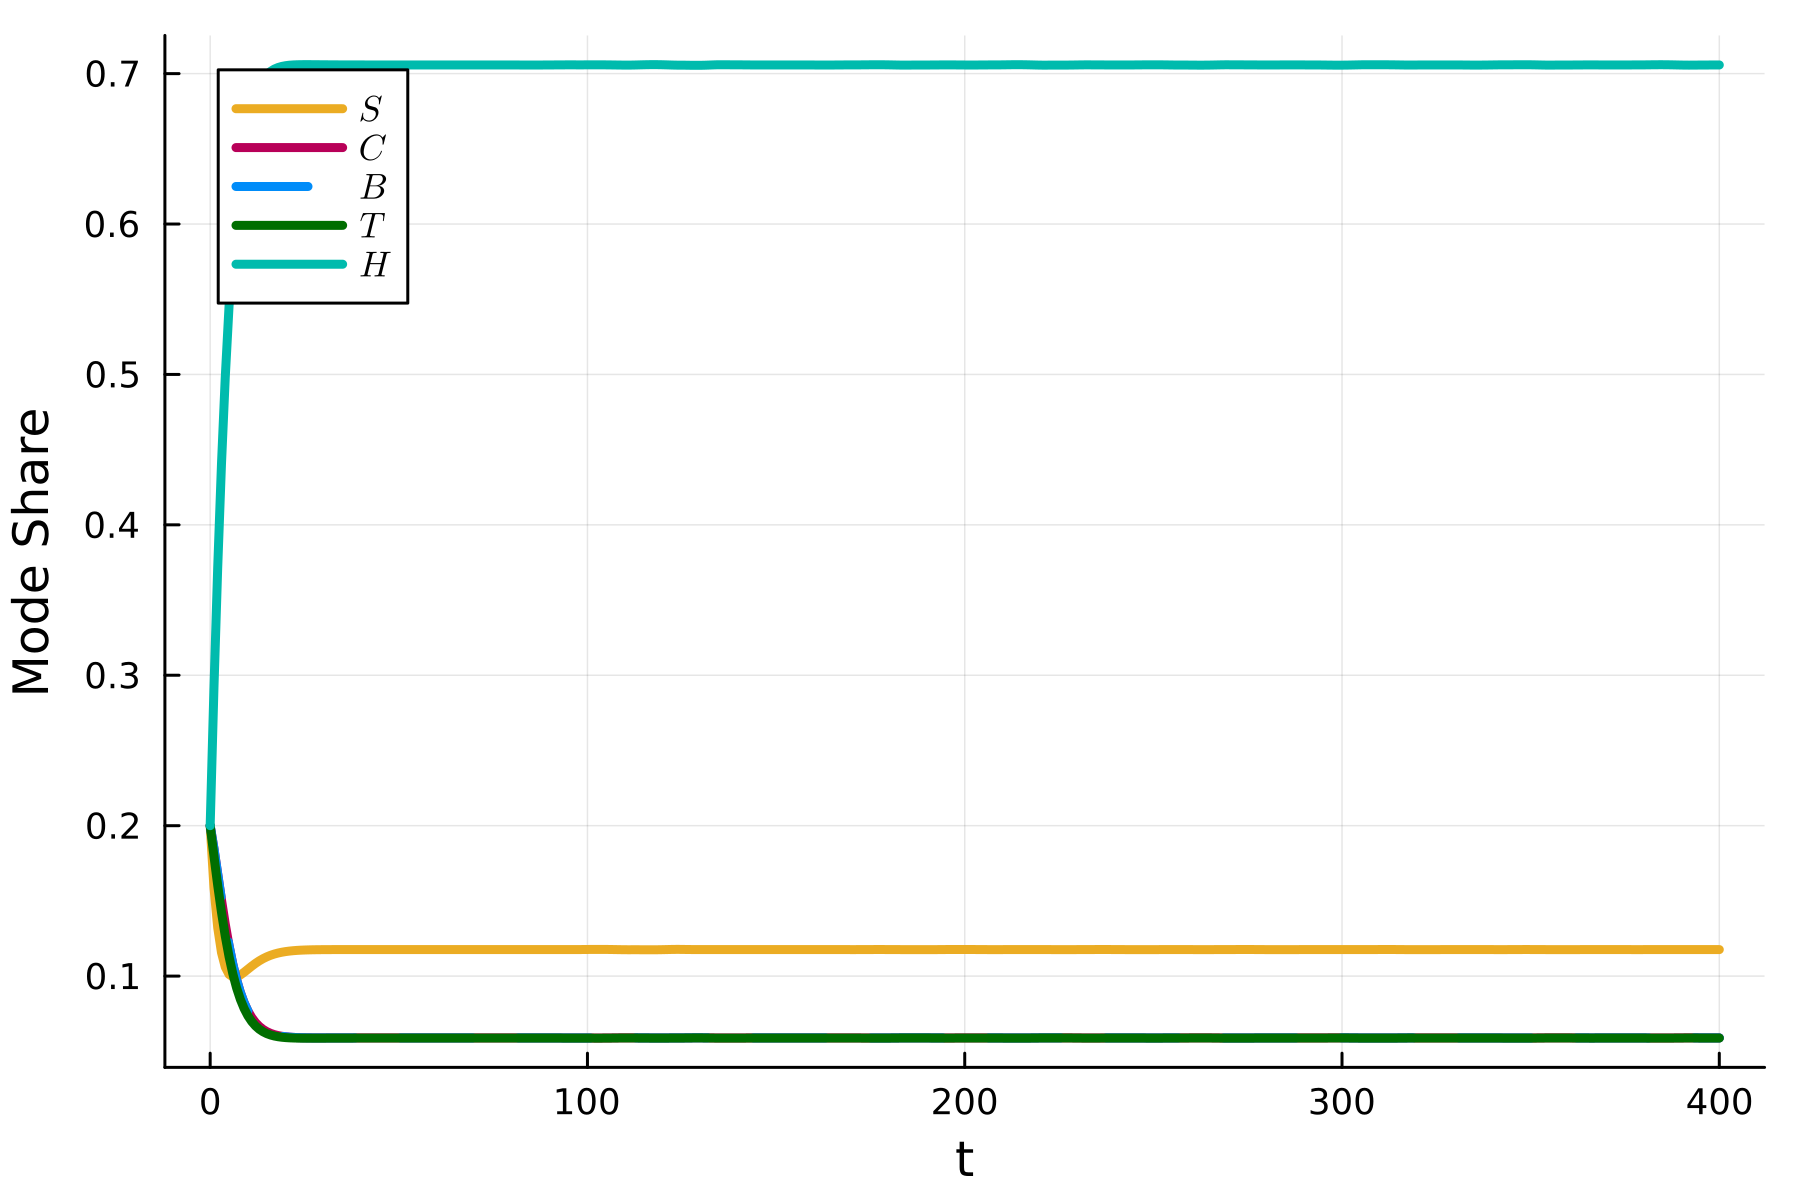

In [54]:
par1 = (alphaC=0.1,alphaB=0.1,alphaT=0.1,beta=0.2,omegaC=0.2,omegaB=0.2,
    k=0.3,n=4,gamma = 0.05)

u0 = [0.2,0.2,0.2,0.2,0.0]
#u0 = [0.00216054 0.01280848 0.95987615 0.02469186]
tspan=(0.0,400.0)

prob_4d = ODEProblem(model_4d_in_out!,u0,tspan,par1)
sol4d = DifferentialEquations.solve(prob_4d,saveat = 1.0,Tsit5())
S4,C4,B4,T4 = sol4d[1,:],sol4d[2,:],sol4d[3,:],sol4d[4,:]
H4 = 1 .- S4 .- C4 .- B4 .-T4

p1 = plot(sol4d.t, vec(S4), label = L"S",  lw=3, color = pal[1],xlabel = "t",ylabel = "Mode Share",dpi = 300)
plot!(p1, sol4d.t, vec(C4), label = L"C",   lw=3, color = pal[2])
plot!(p1, sol4d.t, vec(B4), label = L"B",   lw=3, color = pal[3],linestyle = :dash)
plot!(p1, sol4d.t, vec(T4), label = L"T",   lw=3, color = pal[4])
plot!(p1, sol4d.t, vec(H4), label = L"H",   lw=3, color = pal[5])

In [49]:
base_clear = clear_rate(sol4d,par1)

0.03529494097856989

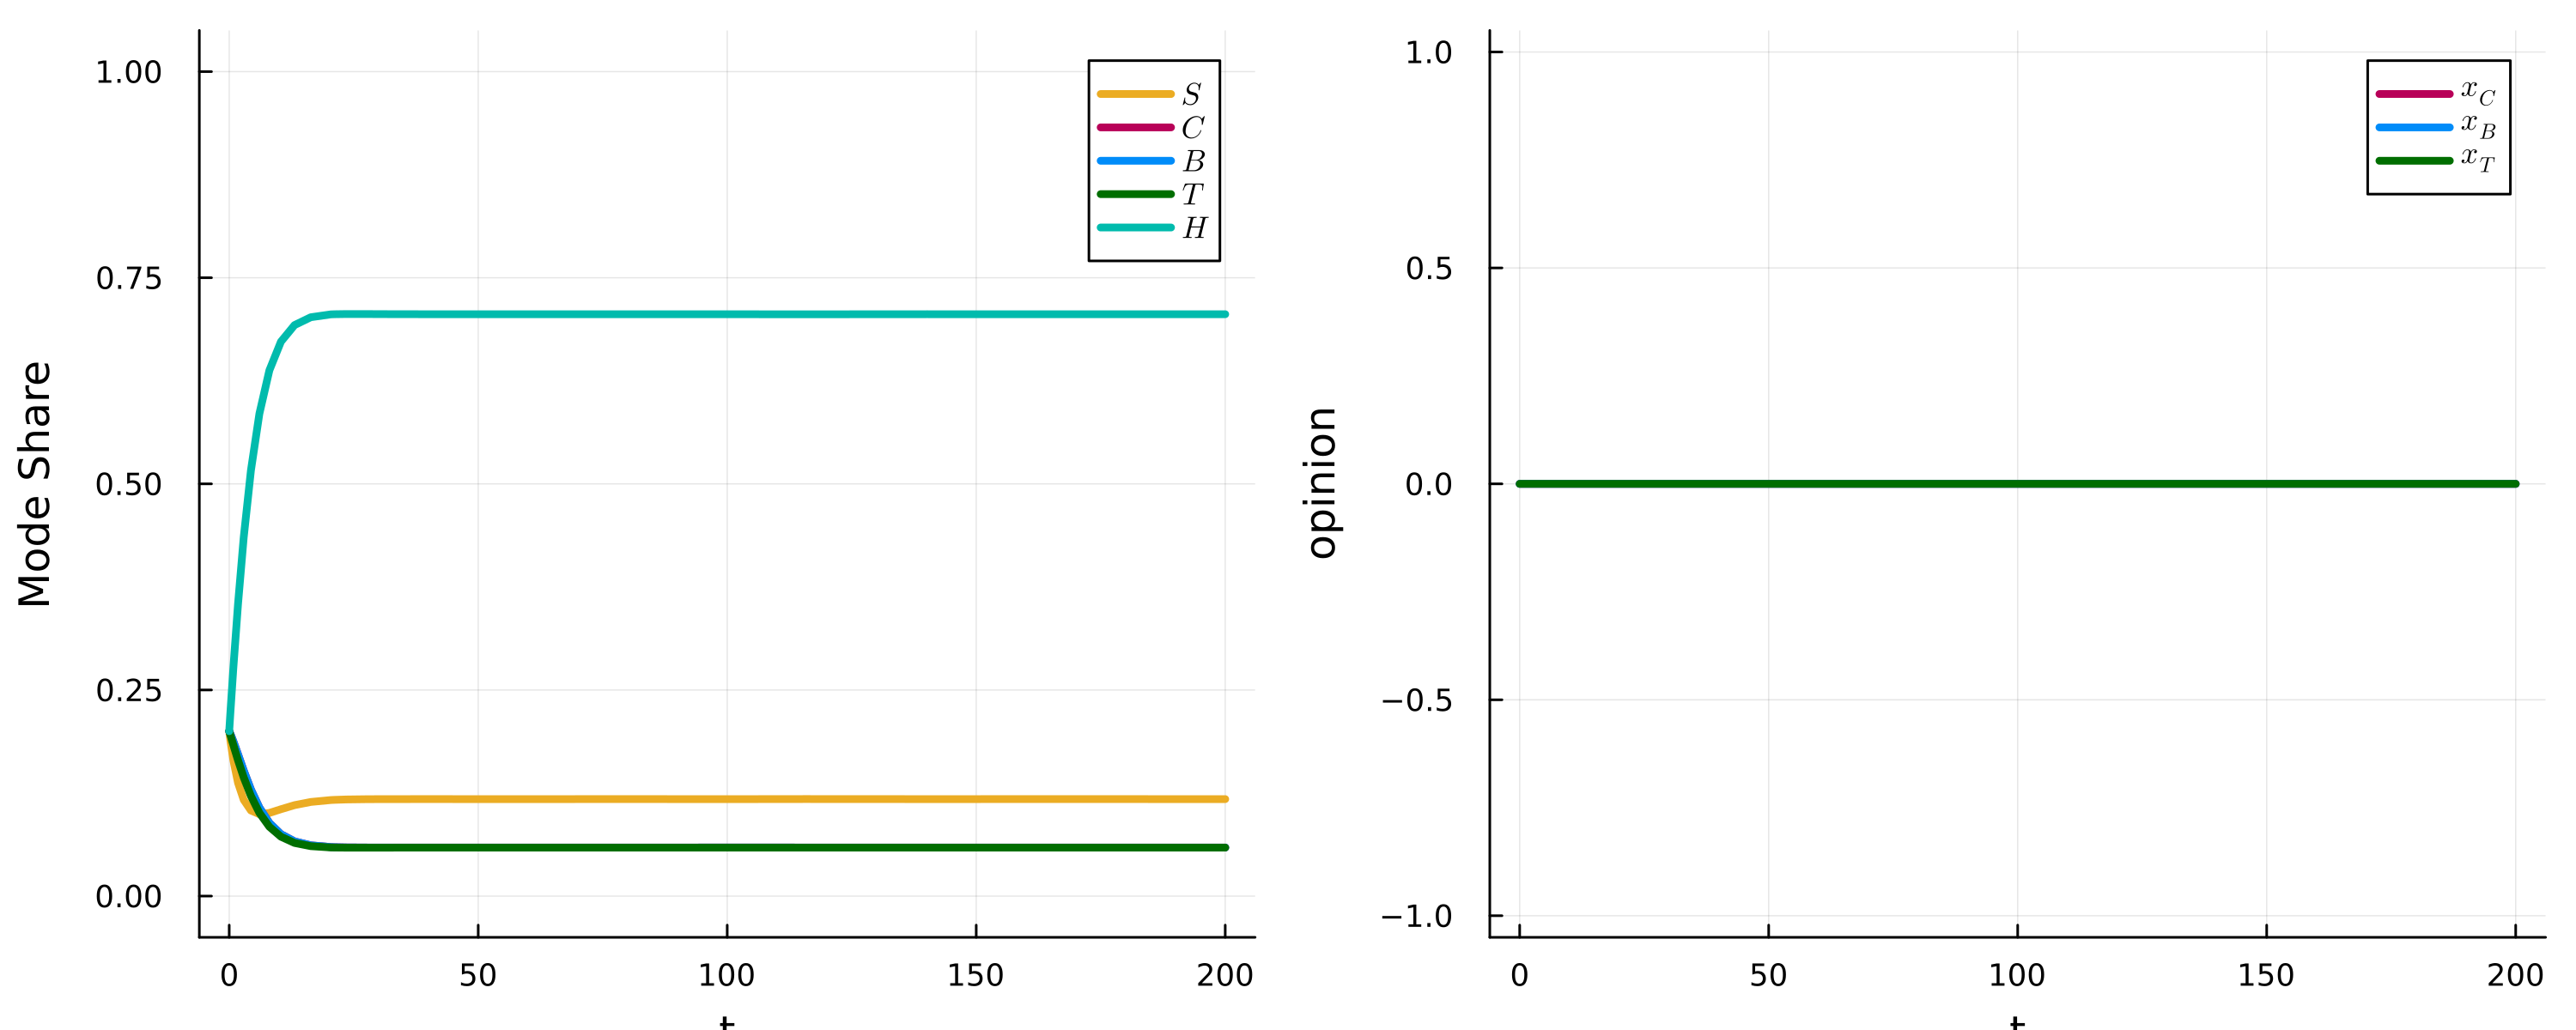

In [78]:
par2 = (alphaC=0.1,alphaB=0.1,alphaT=0.1,beta=0.2,omegaC=0.2,omegaB=0.2,
    k=0.3,n=4,u=0.0,aC=1.0,aB=1.0,aT=1.0,aBC=-0.1,aTC=-0.1,bC=-0.5,
    aCB=-0.1,aTB=0.1,bB=-0.5,aCT=-0.1,aBT=0.1,bT=1.0,tau = 3,gamma = 0.05,b0C=0.00,b0B=0.0,b0T=0.0) # weaker opinions influencing each other (works)

u0 = [0.2,0.2,0.2,0.2,0.0, 0.0,0.0,0]
tspan=(0.0,200.0)

prob_7d = ODEProblem(model_7d_in_out_avg!,u0,tspan,par2)
sol7d = DifferentialEquations.solve(prob_7d)
S,C,B,T,xC,xB,xT = sol7d[1,:],sol7d[2,:],sol7d[3,:],sol7d[4,:],sol7d[5,:],sol7d[6,:],sol7d[7,:]
H = 1 .- S .- C .- B .-T

p1 = plot(sol7d.t, vec(S), label = L"S",  lw=3, ylims=(-0.05,1.05), color = pal[1],xlabel = "t",ylabel = "Mode Share")
plot!(p1, sol7d.t, vec(C), label = L"C",   lw=3, color = pal[2])
plot!(p1, sol7d.t, vec(B), label = L"B",   lw=3, color = pal[3])
plot!(p1, sol7d.t, vec(T), label = L"T",   lw=3, color = pal[4])
plot!(p1, sol7d.t, vec(H), label = L"H",   lw=3, color = pal[5])

p2 = plot(sol7d.t, vec(xC), label = L"x_C", lw=3, ylims=(-1.05,1.05), color = pal[2],xlabel ="t",ylabel = "opinion")
plot!(p2, sol7d.t, vec(xB), label = L"x_B", lw=3, color = pal[3])
plot!(p2, sol7d.t, vec(xT), label = L"x_T", lw=3, color = pal[4])

FIG = plot(p1, p2, size=(1000,400),dpi = 300,left_margin = 5mm)

In [46]:
clear_rate(sol7d,par2)

0.035287942757156014

In [47]:
base_clear

0.03529494097856989

In [81]:
us = LinRange(0.00,2,200)
u0 = [1.0,0.0,0.0,0.0,-1.0,1.0,1.0,0.0,0.0] # transit centric ic
#u0 = [1.0,0.0,0.0,0.0,1.0,-1.0,-1.0,0,0] # car centric ic
u0 = [1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0] # IC gives the kink (neutral)
u0 = [0.2,0.2,0.2,0.2,0,0,0,0]
clears = []
Hin = []

for u in us
    par = (alphaC=0.1,alphaB=0.1,alphaT=0.1,beta=0.2,omegaC=0.2,omegaB=0.2,
        k=0.3,n=4,u=u,aC=1.0,aB=1.0,aT=1.0,aBC=-0.1,aTC=-0.1,bC=-0.5,
        aCB=-0.1,aTB=0.1,bB=-0.5,aCT=-0.1,aBT=0.1,bT=1.0,tau = 3,gamma = 0.05,b0C=0.00,b0B=0.0,b0T=0.0)
    prob = ODEProblem(model_7d_in_out_avg!,u0,tspan,par)
    sol = DifferentialEquations.solve(prob)
    push!(clears, copy(clear_rate(sol,par)))
    push!(Hin,copy(sol[8,end]))
end

In [82]:
Hin

200-element Vector{Any}:
 7.459097148573256
 7.459100406016202
 7.459103772892916
 7.459107194872076
 7.459110677117917
 7.459114215882159
 7.459117814641545
 7.459121475159221
 7.45912519931687
 7.459128989099445
 ⋮
 7.460888199738491
 7.460890873679312
 7.4608935305836015
 7.4608961720134195
 7.460898055636322
 7.460901124443254
 7.46090368446191
 7.460906233925029
 7.460908769080965

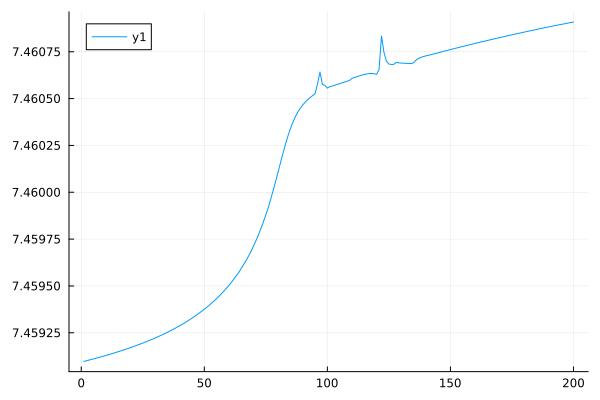

In [83]:
plot(Hin)